In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":

    PROJECT_ROOT = PROJECT_ROOT.parent


results = pd.read_csv(

    PROJECT_ROOT

    / "reports/benchmark_results.csv"
)

results

,dataset,rows,input_size_mib,repetitions,pandas_median_seconds,spark_median_seconds,spark_speedup,output_matches,pandas_runs_seconds,spark_runs_seconds,spark_startup_seconds
0,events_10000.parquet,10000,0.2386,3,0.010392,0.259850,0.039991,True,0.015886;0.009940;0.010392,0.347932;0.250768;0.259850,8.338602
1,events_100000.parquet,100000,1.7582,3,0.016050,0.218216,0.073552,True,0.018233;0.015160;0.016050,0.225155;0.218216;0.190970,8.338602
2,events_1000000.parquet,1000000,17.5470,3,0.076181,0.289704,0.262960,True,0.074558;0.076181;0.084675,0.327499;0.289704;0.251329,8.338602


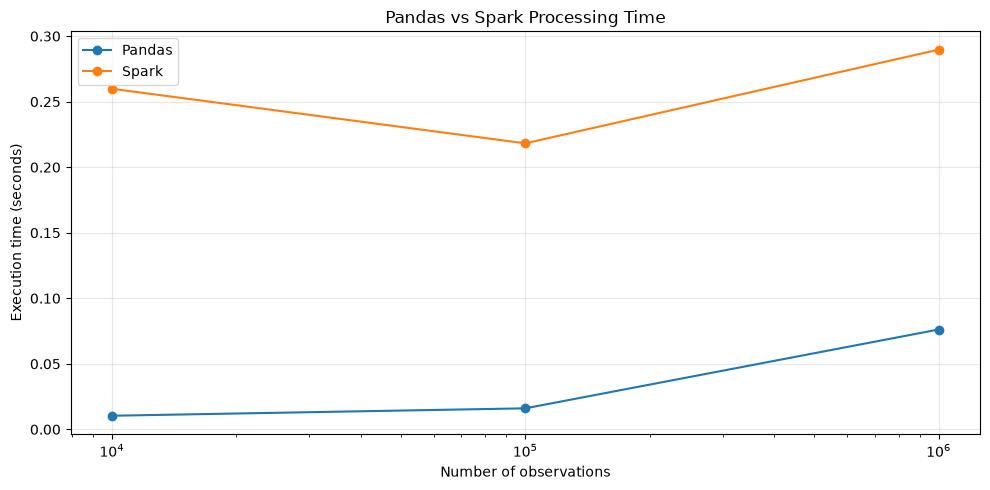

In [2]:
plt.figure(figsize=(10, 5))

plt.plot(

    results["rows"],

    results["pandas_median_seconds"],

    marker="o",

    label="Pandas",
)

plt.plot(

    results["rows"],

    results["spark_median_seconds"],

    marker="o",

    label="Spark",
)

plt.xscale("log")

plt.xlabel("Number of observations")

plt.ylabel("Execution time (seconds)")

plt.title("Pandas vs Spark Processing Time")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

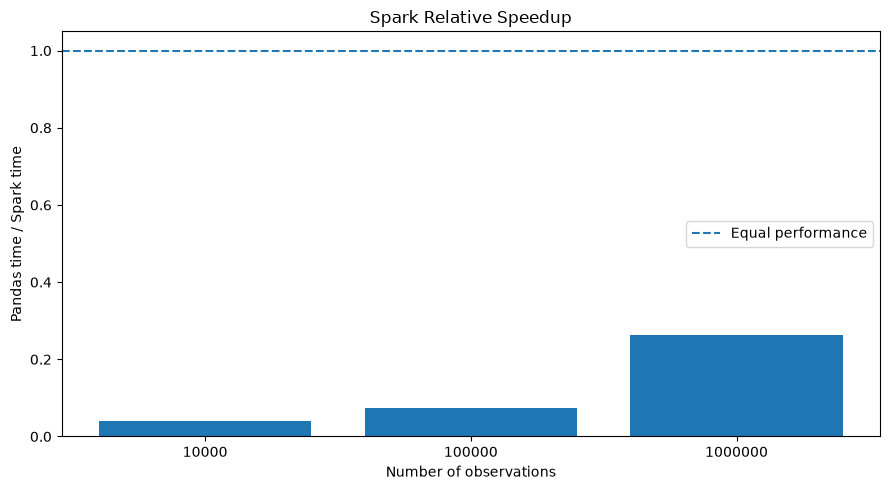

In [3]:
plt.figure(figsize=(9, 5))

plt.bar(

    results["rows"].astype(str),

    results["spark_speedup"],
)

plt.axhline(

    y=1,

    linestyle="--",

    label="Equal performance",
)

plt.xlabel("Number of observations")

plt.ylabel("Pandas time / Spark time")

plt.title("Spark Relative Speedup")

plt.legend()

plt.tight_layout()

plt.show()

In [4]:
results[

    [
        "rows",
        "output_matches",
        "repetitions",
    ]

]

,rows,output_matches,repetitions
0,10000,True,3
1,100000,True,3
2,1000000,True,3


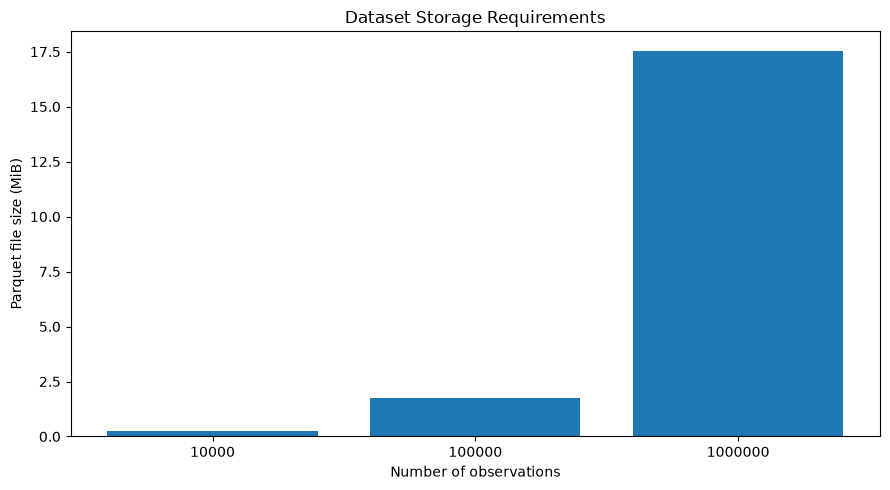

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(

    results["rows"].astype(str),

    results["input_size_mib"],
)

plt.xlabel("Number of observations")

plt.ylabel("Parquet file size (MiB)")

plt.title("Dataset Storage Requirements")

plt.tight_layout()

plt.show()